In [77]:
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd
import dask.dataframe as dd
import numpy as np
import distance

In [6]:
path2file = "../../Downloads/ir_2022-03-22_0158_62392d4210ba7/airr-covid-19.tsv"
# Be careful about the sep (check if it is ; or something else and add it to the
# function below as parameter if so
dataset = pd.read_csv(path2file, sep='\t')


In [7]:
dataset.head()

,sequence_id,sequence,sequence_aa,rev_comp,productive,vj_in_frame,stop_codon,complete_vdj,locus,v_call,...,consensus_count,duplicate_count,cell_id,clone_id,rearrangement_id,repertoire_id,sample_processing_id,data_processing_id,germline_database,rearrangement_set_id
0,615769ad0de387f42b297aa3,GAGCTCTGAGAGAGGAGCCTTAGCCCTGGATTCCAAGGCCTATCCA...,NaN,NaN,T,T,F,NaN,IGH,IGHV3-21*01,...,107,NaN,NaN,NaN,NaN,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,NaN,NaN
1,615769ad0de387f42b297aa4,GAGCTCTGAGAGAGGAGCCTTAGCCCTGGATTCCAAGGCCTATCCA...,NaN,NaN,T,T,F,NaN,IGH,IGHV3-21*01,...,107,NaN,NaN,NaN,NaN,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,NaN,NaN
2,615769ad0de387f42b297aa5,GAGCTCTGAGAGAGGAGCCTTAGCCCTGGATTCCAAGGCCTATCCA...,NaN,NaN,T,T,F,NaN,IGH,IGHV3-21*01,...,107,NaN,NaN,NaN,NaN,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,NaN,NaN
3,615769ad0de387f42b297aa6,GATCACACAACAGCCACATCCCTCCCCTACAGAAGCCCCCAGAGCG...,NaN,NaN,T,T,F,NaN,IGH,IGHV1-24*01,...,1,NaN,NaN,NaN,NaN,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,NaN,NaN
4,615769ad0de387f42b297aa7,GGCTTTCTGAGAGTCATGGATCCCATGTGGAAGAAAATGAAGCACC...,NaN,NaN,T,T,F,NaN,IGH,IGHV4-39*01,...,1,NaN,NaN,NaN,NaN,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,615623b16d7bc19b84b9ae45,NaN,NaN


In [32]:
#identify significant ambiguities in allele assignment
for string in np.unique(dataset['v_call'].array):
    alleles = string.split(', or ')
    ids = [allele.partition('-')[2].partition('*')[0] for allele in alleles]
    ids = [id.partition('-')[0] for id in ids]
    if len(np.unique(ids)) != 1:
        #print(string)

SyntaxError: unexpected EOF while parsing (<ipython-input-32-cc9cdcfe59ab>, line 7)

In [90]:
germ_dist = np.zeros(len(dataset))
v_reg_seqs  = ["" for x in range(len(dataset))]
v_reg_germ = ["" for x in range(len(dataset))]
v_as = ["" for x in range(len(dataset))]
for i in range(0,len(dataset)):
    v_as[i] = dataset['v_call'][i].partition(', or ')[0].partition('*')[0]
    v_reg_end = dataset['germline_alignment'][i].find('N')
    v_reg_germ[i] = dataset['germline_alignment'][i][:v_reg_end]
    v_reg_seqs[i] = dataset['sequence_alignment'][i][:v_reg_end]
    germ_dist[i] = distance.hamming(v_reg_germ[i],v_reg_seqs[i])
v_reg_seqs = np.array(v_reg_seqs)
v_reg_germ = np.array(v_reg_germ)
v_as = np.array(v_as)

In [52]:
big_germ = np.array(v_reg_germ)[germ_dist > 20]
big_seq = np.array(v_reg_seqs)[germ_dist > 20]

In [91]:
sum = 0.0
for v_allele in np.unique(v_as):
    print(v_allele)
    sum +=np.sum(v_as == v_allele)/len(v_as)
    print(np.sum(v_as == v_allele)/len(v_as))
print(sum)

IGHV1-18
0.02195447843715444
IGHV1-2
0.09247143383708072
IGHV1-24
0.03879469222263177
IGHV1-46
0.02144765941761887
IGHV1-58
0.00027644673792849247
IGHV1-69
0.05296258754146701
IGHV1-69-2
0.002050313306302986
IGHV1-8
0.030846848507187614
IGHV2-26
0.003271286398820494
IGHV2-5
0.00370899373387394
IGHV2-70
0.0007371913011426465
IGHV3-11
0.0040315149281238485
IGHV3-13
0.002027276078142278
IGHV3-15
0.021724106155547363
IGHV3-20
0.002787504607445632
IGHV3-21
0.07097769996314043
IGHV3-23
0.05158035385182455
IGHV3-30
0.047364541098415036
IGHV3-30-3
0.022783818650939917
IGHV3-33
0.019374308883155177
IGHV3-43
0.008915407298193881
IGHV3-48
0.016932362698120162
IGHV3-49
0.007441024695908589
IGHV3-53
0.041605234058238114
IGHV3-64
0.0004607445632141541
IGHV3-66
0.0008063029856247696
IGHV3-69-1
6.911168448212312e-05
IGHV3-7
0.03927847401400664
IGHV3-71
2.3037228160707704e-05
IGHV3-72
0.005229450792480649
IGHV3-73
0.003593807593070402
IGHV3-74
0.015688352377441945
IGHV3-9
0.04326391448580907
IGHV3-NL1


In [ ]:
for v_allele in ['IGHV4-59']:#np.unique(v_as):
    germ_mut_n = np.unique(germ_dist[v_as == v_allele])
    print(germ_mut_n)
    mean_hamming = np.zeros(len(germ_mut_n))
    

    for k in tqdm(range(1,len(germ_mut_n))):
        n = germ_mut_n[k]
        seqs = v_reg_seqs[(v_as == v_allele) & (germ_dist == n)]
        dists = []
        print(len(seqs))
        for i in range(0,len(seqs)):
            for j in range(0,len(seqs)):
                if i != j:
                    dists.append(distance.levenshtein(seqs[i],seqs[j]))
                    print(dists)
        if not dists:
            mean_hamming[k] = np.mean(np.array(dists))

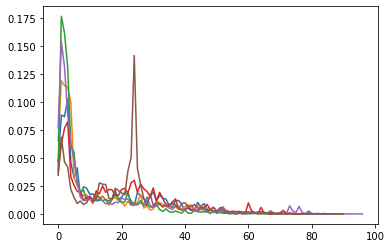

In [93]:
for v_allele in np.unique(v_as):
    if np.sum(v_as == v_allele)/len(v_as) > 0.05:
        bins = np.arange(0,np.max(germ_dist[v_as == v_allele]),1)
        hist = np.histogram(germ_dist[v_as == v_allele],bins,density = True)
        plt.plot(hist[1][0:-1],hist[0][0:])
    #plt.yscale('log')

In [36]:
for i in dataset.columns:
    print(i)
    print(dataset[i][1])

sequence_id
615769ad0de387f42b297aa4
sequence
GAGCTCTGAGAGAGGAGCCTTAGCCCTGGATTCCAAGGCCTATCCACTTGGTGATCAGCACTGAGCACCGAGGATTCACCATGGAACTGGGGCTCCGCTGGGTTTTCCTTGTTGCTATTTTAGAAGGTGTCCAGTGTGAGGTGCAGCTGGTGGAGTCTGGGGGAGGCCTGGTCAAGCCTGGGGGGTCCCTGAGACTCTCCTGTGCAGCCTCTGGATTCACCTTCAGTAGCTATAGCATGAACTGGGTCCGCCAGGCTCCAGGGAAGGGGCTGGAGTGGGTCTCATCCATTAGTAGTAGTAGTAGTTACATATACTACGCAGACTCAGTGAAGGGCCGATTCACCATCTCCAGAGACAACGCCAAGAACTCACTGTATCTGCAAATGAACAGCCTGAGAGCCGAGGACGCGGCTGTGTTTTACTGTGCGAGAGTGATTCGGTGGGGGGACGATTTTTGGAGTGGTTATTATCCCGGGGCCCTTGACTACTGGGGCCAGGGAACCCTGGTCACCGTCTCCTCAGCCTCCACCAAGGGCC
sequence_aa
nan
rev_comp
nan
productive
T
vj_in_frame
T
stop_codon
F
complete_vdj
nan
locus
IGH
v_call
IGHV3-21*01
d_call
IGHD3-3*01
d2_call
nan
j_call
IGHJ4*02
c_call
nan
sequence_alignment
GAGGTGCAGCTGGTGGAGTCTGGGGGA...GGCCTGGTCAAGCCTGGGGGGTCCCTGAGACTCTCCTGTGCAGCCTCTGGATTCACCTTC............AGTAGCTATAGCATGAACTGGGTCCGCCAGGCTCCAGGGAAGGGGCTGGAGTGGGTCTCATCCATTAGTAGTAGT......AGTAGTTACATATACTACGCAGACTCAGTGAAG...GGCCGA

In [61]:
np.sum(v_as == v_as[8])/len(v_as)

0.011403427939550313